# PH5720 — Problem Set 6
**Department of Physics | IIT Madras | January–May 2025**


## Question 1 — Data Fitting

By the method of least squares, find the straight line that best fits the following data. Plot the data points and the best-fit line.

| $x$ | 8.213 | 7.402 | 6.876 | 5.491 | 5.196 |
|---|---:|---:|---:|---:|---:|
| $y$ | 3.261 | 2.52 | 2.239 | 1.299 | 1.175 |
| $\sigma$ | $9.71\times10^{-2}$ | $5.59\times10^{-2}$ | $7.08\times10^{-2}$ | $6.83\times10^{-2}$ | $8.93\times10^{-2}$ |

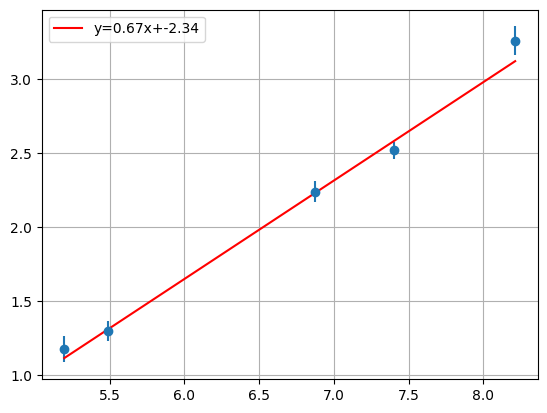

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
x=np.array([8.213, 7.402, 6.876, 5.491, 5.196])
y=np.array([3.261, 2.52, 2.239, 1.299, 1.175])
sigma=np.array([9.71e-2, 5.59e-2, 7.08e-2, 6.83e-2, 8.93e-2])
weights=1/(sigma**2)
s=sum(weights)
sx=sum(weights*x)
sy=sum(weights*y)
sxy=sum(weights*x*y)
sxx=sum(weights*x**2)

m=(s*sxy-sx*sy)/(s*sxx-sx*sx)
c=(sy-m*sx)/s
X=np.linspace(min(x),max(x),100)
Y=m*X+c

plt.errorbar(x,y,yerr=sigma,fmt='o')
plt.plot(X,Y,'r',label=f'y={m:.2f}x+{c:.2f}')
plt.legend()
plt.grid(True)
plt.show()


## Question 2

Repeat Problem 1 using the Python module (e.g., `curvefit`).

Compare the values of the parameters from the two methods.

Plot the data points and the best-fit lines from the two methods.

0.6656028716557747 -2.3430681810546625


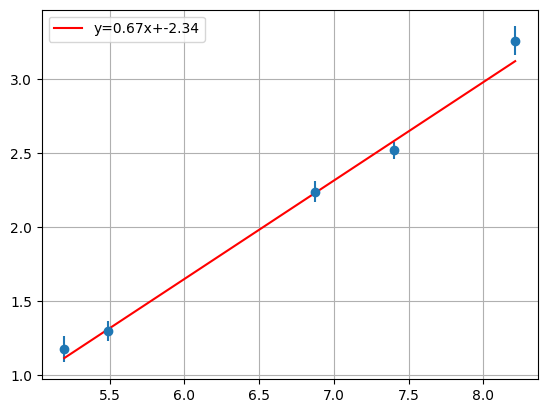

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
x=np.array([8.213, 7.402, 6.876, 5.491, 5.196])
y=np.array([3.261, 2.52, 2.239, 1.299, 1.175])
sigma=np.array([9.71e-2, 5.59e-2, 7.08e-2, 6.83e-2, 8.93e-2])

def f(x,m,c):
    return m*x+c
p,q=curve_fit(f,x,y,sigma=sigma)
m,c=p
print(m,c)
X=np.linspace(min(x),max(x),100)
Y=m*X+c

plt.errorbar(x,y,yerr=sigma,fmt='o')
plt.plot(X,Y,'r',label=f'y={m:.2f}x+{c:.2f}')
plt.legend()
plt.grid(True)
plt.show()


## Question 3

Fit a second-order polynomial by taking $x$ as the independent variable.

| $x$ | 1 | 1 | 2 | 3 | 4 |
|---|---:|---:|---:|---:|---:|
| $y$ | 1 | 5 | 10 | 22 | 38 |

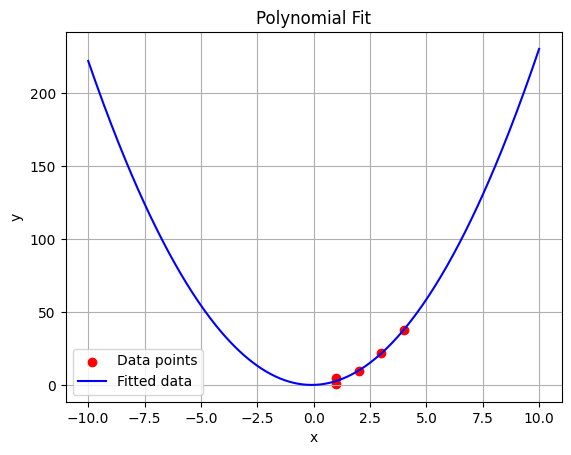

In [12]:
import numpy.polynomial.polynomial as poly
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1, 1, 2, 3, 4])
y = np.array([1, 5, 10, 22, 38])

coeffs = poly.polyfit(x, y, 2)
X = np.linspace(-10, 10, 300)

yfit = poly.polyval(X, coeffs)

plt.scatter(x, y, color='r', label='Data points')   
plt.plot(X, yfit, 'b', label='Fitted data')       
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Fit')
plt.grid()
plt.show()


## Question 4 — Integration

Plot and integrate the tabulated data given below by a suitable method. Take the endpoints of the table as the integration limits.

| $x$ | 1.34 | 1.46 | 1.52 | 1.6 | 1.87 | 2.03 | 2.18 | 2.8 | 3.2 | 3.8 | 4.15 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| $f(x)$ | 1.5 | 2.3 | 2.3 | 2.4 | 2.5 | 3.2 | 4.9 | 4.7 | 3.4 | 7.8 | 17.1 |

In [13]:
x=np.array([1.34,1.46,1.52,1.6,1.87,2.03,2.18,2.8,3.2,3.8,4.15])
y=np.array([1.5,2.3,2.3,2.4,2.5,3.2,4.9,4.7,3.4,7.8,17.1])
def trap(x,y):

    t=0
    for i in range(len(x)-1):
    
        t=t+(-x[i]+x[i+1])*0.5*(y[i]+y[i+1])

    return t

b=np.sum(trap(x,y))
print('The intregration= ',b)

The intregration=  14.592500000000005


## Question 5 — Numerical Integration

Write a Python function `trap(f, a, b, N)` which will evaluate the integral

$$
\int_a^b f(x)\,dx
$$

using the trapezoidal rule with $N$ steps.

Also, develop a similar function `simp(f, a, b, N)` for Simpson’s rule.

Use these functions to evaluate the numerical integrals in the subsequent problems, wherever applicable.

Evaluate the following integrals over the interval $[a,b]$, divided into

$$
N=2^n,\qquad n=1,2,3,\ldots,10
$$

intervals, using:

1. The trapezoidal rule.
2. Simpson’s rule.

| $f(x)$ | $x^2$ | $\sin(x)$ | $\left(\frac{\sin x}{x}\right)^2$ |
|---|---:|---:|---:|
| $a$ | $-1$ | $0$ | $0$ |
| $b$ | $1$ | $\pi$ | $\infty$ |
| Analytical value | $\frac{2}{3}$ | $2$ | $\frac{\pi}{2}$ |

Let $y_N$ be the numerical result for $N$ intervals used, and let $y_{AN}$ be the analytical result. We define the relative error as

$$
e(N)=\left|\frac{y_N-y_{AN}}{y_{AN}}\right|.
$$

The error depends on $N$. Show a plot of $\log e(N)$ against $\log N$ for all the integrals.

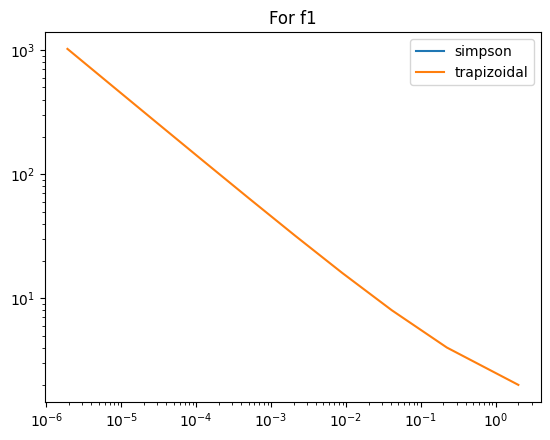

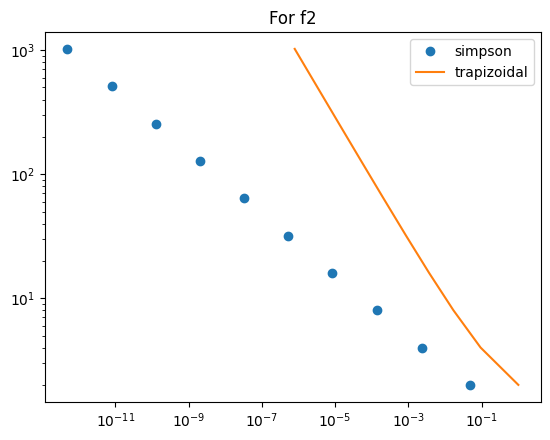

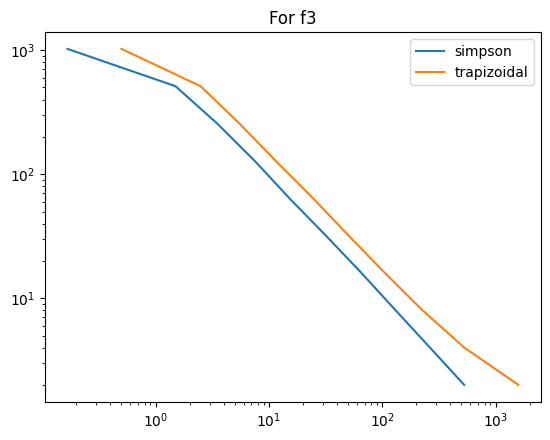

In [14]:
def trap(f,a,b,N):
    x=np.linspace(a,b,N)
    y=f(x)
    t=0
    for i in range(N-1):
        t=t+(-x[i]+x[i+1])*0.5*(y[i]+y[i+1])
    return t
def simp(f,a,b,N):
    if N%2==0:
        N=N+1
    x,h=np.linspace(a,b,N,retstep=True)
    y=f(x)
    s_odd=4*sum(f(a+i*h) for i in range(1,N,2))
    s_even=2*sum(f(a+i*h) for i in range(2,N-1,2))
    I=(h/3)*(f(a)+f(b)+s_odd+s_even)
    return I

def f1(x):
    return x**2    #-1 t6o 1  an=2/3
def f2(x):
    return np.sin(x)   #0 to pi   an=2
def f3(x):
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(x==0, 1.0, np.sin(x)/x)  #0 to infinity  an=pi

inf=10000
N=[2**n for n in range(1,11,1)]

E1_t,E2_t,E3_t=[],[],[]
E1_s,E2_s,E3_s=[],[],[]
for m in N:
    e1_t=abs((trap(f1,-1,1,m)-(2/3))/(2/3))
    e1_s=abs((simp(f1,-1,1,m)-(2/3))/(2/3))
    E1_t.append(e1_t)
    E1_s.append(e1_s)
    e2_t=abs((trap(f2,0,np.pi,m)-2)/2)
    e2_s=abs((simp(f2,0,np.pi,m)-2)/2)
    E2_t.append(e2_t)
    E2_s.append(e2_s)
    e3_t=abs((trap(f3,0,inf,m)-np.pi)/np.pi)
    e3_s=abs((simp(f3,0,inf,m)-np.pi)/np.pi)
    E3_s.append(e3_s)
    E3_t.append(e3_t)
plt.loglog(E1_s,N,label='simpson')
plt.loglog(E1_t,N,label='trapizoidal')
plt.title('For f1')
plt.legend()
plt.show()
plt.loglog(E2_s,N,'o',label='simpson')
plt.loglog(E2_t,N,label='trapizoidal')
plt.title('For f2')
plt.legend()
plt.show()
plt.loglog(E3_s,N,label='simpson')
plt.loglog(E3_t,N,label='trapizoidal')
plt.title('For f3')
plt.legend()
plt.show()
#print(E2_s)

## Question 6 — Numerical Integration Methods

Evaluate the following integrals:

| $f(x)$ | $x^6-7x^3+5$ | $x^2e^{x-1}$ | $\frac{\sin x}{\sqrt{x}}$ |
|---|---:|---:|---:|
| $a$ | $-1$ | $0$ | $0$ |
| $b$ | $1$ | $5$ | $1$ |

Use the following methods:

1. Trapezoidal rule with 100 points.
2. Simpson's rule with 51 points.
3. Gauss quadrature method with 6 points.

For the Gauss quadrature method, use the following 6-point weights and abscissas:

| $i$ | Weight $w_i$ | Abscissa $x_i$ |
|---:|---:|---:|
| 1 | 0.3607615730481386 | 0.6612093864662645 |
| 2 | 0.3607615730481386 | -0.6612093864662645 |
| 3 | 0.4679139345726910 | -0.2386191860831969 |
| 4 | 0.4679139345726910 | 0.2386191860831969 |
| 5 | 0.1713244923791704 | -0.9324695142031521 |
| 6 | 0.1713244923791704 | 0.9324695142031521 |

Compare the values obtained using the three methods in a table.

In [1]:
import numpy as np
import math


# Define the functions
def f1(x):
    return x ** 6 - 7 * x ** 3 + 5


def f2(x):
    return x ** 2 * math.exp(x - 1)


def f3(x):
    if x == 0:  # Handle singularity at x = 0
        return 0
    return math.sin(x) / math.sqrt(x)


# Trapezoidal Rule
def trapezoidal_rule(func, a, b, n):
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = [func(i) for i in x]
    return h * (y[0] / 2 + sum(y[1:-1]) + y[-1] / 2)


# Simpson's Rule
def simpsons_rule(func, a, b, n):
    if n % 2 == 0:
        n += 1  # Simpson's rule requires odd number of intervals
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = [func(i) for i in x]
    return h / 3 * (y[0] + sum(4 * y[i] for i in range(1, n, 2)) + sum(2 * y[i] for i in range(2, n - 1, 2)) + y[-1])


# Gauss Quadrature Method
def gauss_quadrature(func, a, b, n):
    weights = [0.36076157304813866, 0.36076157304813866,
               0.46791393457269104, 0.46791393457269104,
               0.17132449237917035, 0.17132449237917035]
    abscissas = [-0.6612093864662645, 0.6612093864662645,
                 -0.2386191860831969, 0.2386191860831969,
                 -0.9324695142031521, 0.9324695142031521]

    integral = 0
    for i in range(n):
        xi = (b - a) / 2 * abscissas[i] + (b + a) / 2
        wi = weights[i]
        integral += wi * func(xi)

    return (b - a) / 2 * integral


# Integration limits and number of points
limits = [
    (-1, 1),  # For f1(x)
    (0, 5),  # For f2(x)
    (1e-6, 1)  # For f3(x), avoid singularity at x=0 by starting from a small positive value
]
n_trap = 100
n_simp = 51
n_gauss = 6

# Evaluate integrals for each function using all three methods
functions = [f1, f2, f3]
results = []

for i, func in enumerate(functions):
    a, b = limits[i]

    trap_result = trapezoidal_rule(func, a, b, n_trap)
    simp_result = simpsons_rule(func, a, b, n_simp)

    try:
        gauss_result = gauss_quadrature(func, a, b, n_gauss)
    except ValueError:
        gauss_result = "NaN"

    results.append((trap_result, simp_result, gauss_result))

print("Method          | Trapezoidal Rule | Simpson's Rule | Gauss Quadrature")
print("---------------------------------------------------------------------")
for i in range(len(functions)):
    print(f"Function {i + 1}   | {results[i][0]:<16} | {results[i][1]:<14} | {results[i][2]}")


Method          | Trapezoidal Rule | Simpson's Rule | Gauss Quadrature
---------------------------------------------------------------------
Function 1   | 10.286114232384  | 10.305968006351554 | 10.285714285714285
Function 2   | 927.8308743031257 | 808.1444483436882 | 927.4325561898386
Function 3   | 0.6203346407489395 | 0.6038609360489282 | 0.6209162452816924


## Question 7 — 2D Integral

Consider the double integral

$$
I=\int_0^1\int_0^1 f(x,y)\,dx\,dy
$$

with $h=k=0.25$.

### (a) Formulate the Coefficient Matrices

Formulate the two-dimensional trapezoidal and Simpson's coefficient matrices.

You need to use the NumPy function `meshgrid` for this.

### (b) Evaluate the Integral

Evaluate the integral for the following functions:

1. $$f(x,y)=5x^3y+2x$$

2. $$f(x,y)=5xy-y^4$$

In [15]:
import numpy as np

# Define the functions f(x, y)
def f1(x, y):
    return 5 * x**3 * y + 2 * x

def f2(x, y):
    return 5 * x * y - y**4

# Define the grid (h = k = 0.25)
h = k = 0.25
x = np.arange(0, 1 + h, h)  # x-coordinates
y = np.arange(0, 1 + k, k)  # y-coordinates
X, Y = np.meshgrid(x, y)    # Create a grid of points

# Define Trapezoidal coefficient matrix
trap_coefficients = np.ones_like(X)
trap_coefficients[1:-1, :] = 2 *trap_coefficients[1:-1, :] # Double coefficients for interior rows
trap_coefficients[:, 1:-1] *= 2  # Double coefficients for interior columns

# Define Simpson's coefficient matrix
simp_coefficients = np.ones_like(X)
simp_coefficients[1:-1:2, :] *= 4   # Multiply odd rows by 4
simp_coefficients[2:-1:2, :] *= 2   # Multiply even rows by 2
simp_coefficients[:, 1:-1:2] *= 4   # Multiply odd columns by 4
simp_coefficients[:, 2:-1:2] *= 2   # Multiply even columns by 2

# Compute integrals using Trapezoidal Rule
def trapezoidal_integral(f):
    Z = f(X, Y)                       # Evaluate the function on the grid
    integral = h * k * np.sum(Z * trap_coefficients) / 4
    return integral

# Compute integrals using Simpson's Rule
def simpson_integral(f):
    Z = f(X, Y)                       # Evaluate the function on the grid
    integral = h * k * np.sum(Z * simp_coefficients) / 9
    return integral

# Evaluate the integrals for both functions
I_trap_f1 = trapezoidal_integral(f1)
I_simp_f1 = simpson_integral(f1)

I_trap_f2 = trapezoidal_integral(f2)
I_simp_f2 = simpson_integral(f2)

print("Results for f(x, y) = (5x^3y + 2x):")
print(f"Trapezoidal Rule: {I_trap_f1}")
print(f"Simpson's Rule: {I_simp_f1}")

print("\nResults for f(x, y) = (5xy - y^4):")
print(f"Trapezoidal Rule: {I_trap_f2}")
print(f"Simpson's Rule: {I_simp_f2}")


Results for f(x, y) = (5x^3y + 2x):
Trapezoidal Rule: 1.6640625
Simpson's Rule: 1.625

Results for f(x, y) = (5xy - y^4):
Trapezoidal Rule: 1.029296875
Simpson's Rule: 1.0494791666666667


## Question 8 — Adaptive Integration

### (a) Implement Adaptive Trapezoidal Integration

First integrate the entire range. If the integral is defined as

$$
I=\int_a^b f(x)\,dx\equiv I_0,
$$

evaluate it using the trapezoidal rule.

Let this result be called $I_0$.

Define the midpoint

$$
c=\frac{a+b}{2}.
$$

Then split the integral into two parts:

$$
I=\int_a^c f(x)\,dx+\int_c^b f(x)\,dx\equiv I_1.
$$

Let this result, where the integral is split, be called $I_1$.

Compare the results $I_0$ and $I_1$:

$$
|I_0-I_1|<\epsilon,
$$

where $\epsilon$ is a tolerance that you need to specify.

If the error is less than the tolerance $\epsilon$, stop the process. Otherwise, continue by splitting the interval $[a,c]$ further, and repeat the same procedure for the interval $[c,b]$.

Continue until the desired absolute or relative error is obtained. This tolerance is set by the user.

### (b) Compare Fixed-Step and Adaptive Integration

Integrate the following function:

$$
I=\int_0^3\frac{1}{2+x^2}\,dx.
$$

The exact result is

$$
I=\frac{1}{\sqrt{2}}
\tan^{-1}\left(\frac{3}{\sqrt{2}}\right).
$$

Use the trapezoidal rule without the adaptive procedure.

Compare the numerical result for the fixed-step trapezoidal rule against the exact result.

Plot the relative errors for the simple trapezoidal rule on a log-log plot and comment on the results, particularly the convergence with increasing $N$.

For the adaptive algorithm, show that for $N=2$ (this being the starting value), you obtain the tolerance you specify.

Fixed-step Trapezoidal Rule Results:
N=4, Result=0.79693911, Relative Error=2.86968144e-03
N=8, Result=0.79865251, Relative Error=7.25886602e-04
N=16, Result=0.79908744, Relative Error=1.81692665e-04
N=32, Result=0.79919634, Relative Error=4.54370165e-05
N=64, Result=0.79922358, Relative Error=1.13601204e-05

Adaptive Trapezoidal Rule Results:
Tolerance=1e-02, Result=0.80036895, Relative Error=1.42173031e-03
Tolerance=1e-04, Result=0.79924227, Relative Error=1.20231410e-05
Tolerance=1e-06, Result=0.79923274, Relative Error=1.08066735e-07


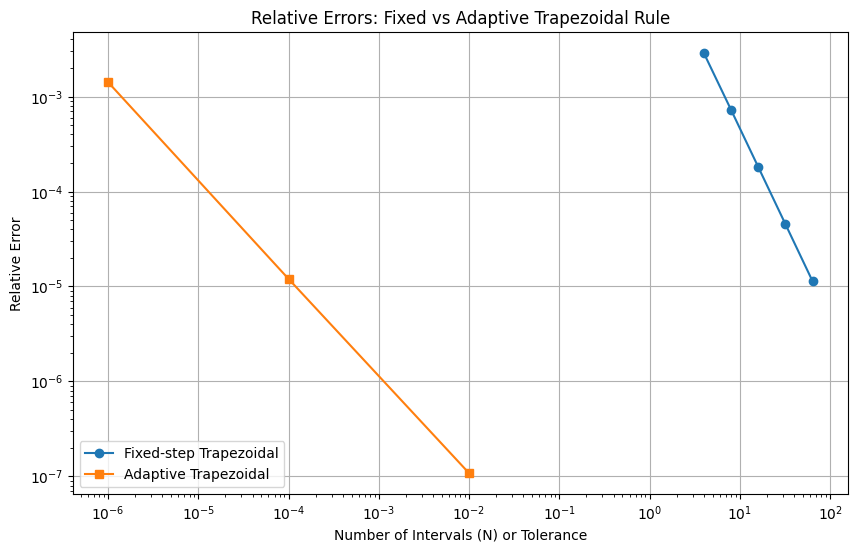

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Define the function
def f(x):
    return 1 / (2 + x**2)

# Exact result of the integral
exact_result = (1 / np.sqrt(2)) * np.arctan(3 / np.sqrt(2))

# Fixed-step Trapezoidal Rule
def trapezoidal_fixed(f, a, b, N):
    h = (b - a) / N
    x = np.linspace(a, b, N + 1)
    y = f(x)
    integral = h * (0.5 * y[0] + np.sum(y[1:-1]) + 0.5 * y[-1])
    return integral

# Adaptive Trapezoidal Rule
def adaptive_trapezoidal(f, a, b, tol):
    I0 = trapezoidal_fixed(f, a, b, 1)  # Initial estimate with one interval
    c = (a + b) / 2
    I1 = trapezoidal_fixed(f, a, c, 1) + trapezoidal_fixed(f, c, b, 1)
    
    if abs(I0 - I1) < tol:
        return I1
    else:
        # Recursively refine intervals
        left_integral = adaptive_trapezoidal(f, a, c, tol / 2)
        right_integral = adaptive_trapezoidal(f, c, b, tol / 2)
        return left_integral + right_integral

# Parameters for fixed-step Trapezoidal Rule
a, b = 0, 3
tolerances = [1e-2, 1e-4, 1e-6]   # Tolerances for adaptive method
N_values = [4, 8, 16, 32, 64]     # Number of intervals for fixed-step method

# Compute fixed-step results and relative errors
fixed_results = []
fixed_errors = []
for N in N_values:
    result = trapezoidal_fixed(f, a, b, N)
    fixed_results.append(result)
    fixed_errors.append(abs(result - exact_result) / abs(exact_result))

# Compute adaptive results and relative errors
adaptive_results = []
adaptive_errors = []
for tol in tolerances:
    result = adaptive_trapezoidal(f, a, b, tol)
    adaptive_results.append(result)
    adaptive_errors.append(abs(result - exact_result) / abs(exact_result))


print("Fixed-step Trapezoidal Rule Results:")
for N, result in zip(N_values, fixed_results):
    print(f"N={N}, Result={result:.8f}, Relative Error={fixed_errors[N_values.index(N)]:.8e}")

print("\nAdaptive Trapezoidal Rule Results:")
for tol, result in zip(tolerances, adaptive_results):
    print(f"Tolerance={tol:.0e}, Result={result:.8f}, Relative Error={adaptive_errors[tolerances.index(tol)]:.8e}")

# Plot relative errors on a log-log scale
plt.figure(figsize=(10, 6))
plt.loglog(N_values, fixed_errors, label="Fixed-step Trapezoidal", marker='o')
plt.loglog(tolerances, adaptive_errors[::-1], label="Adaptive Trapezoidal", marker='s')
plt.xlabel("Number of Intervals (N) or Tolerance")
plt.ylabel("Relative Error")
plt.title("Relative Errors: Fixed vs Adaptive Trapezoidal Rule")
plt.legend()
plt.grid(True)
plt.show()
